# TCS Stock Price Prediction — All 11 ML Models
### Research Journey: OHLCV Only → Feature Engineering → OHLCV + Indicators
**Part A (Set A):** All 11 models on raw OHLCV (5 features)  
**💡 New Idea:** Add 9 Technical Indicators → Set B (14 features)  
**Part B (Set B):** All 11 models with indicators  
**Final:** Comprehensive comparison across all models & feature sets


## Step 0: Data Collection — Download TCS Stock Data from Yahoo Finance

**Source:** Yahoo Finance via `yfinance` library
**Stock:** TCS.NS (TCS listed on NSE — National Stock Exchange, India)
**Period:** 2005-01-01 to 2026-09-24
**Saved as:** TCS.csv

This is the raw data collection step. The downloaded CSV contains:
Open, High, Low, Close, Volume — daily historical data adjusted for stock splits and dividends.

In [1]:
pip install yfinance

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import yfinance as yf
yf.download('TCS.NS', start='2005-01-01', end='2026-09-24').to_csv('TCS.csv')
print("TCS.csv downloaded and saved successfully!")

[*********************100%***********************]  1 of 1 completed

TCS.csv downloaded and saved successfully!


---
## Step 1: Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)


from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

print("All libraries imported successfully!")

---
## Step 2: Load Dataset

In [ ]:
df = pd.read_csv('TCS.csv', skiprows=[1, 2])
df.rename(columns={'Price': 'Date'}, inplace=True)
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)
df.sort_index(inplace=True)

for col in ['Open','High','Low','Close','Volume']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.dropna(inplace=True)
print("Dataset loaded!")
print(f"Rows: {len(df)}")

Dataset loaded!
Rows: 5363


## Step 3: Dataset Overview

In [ ]:
print(f"Shape: {df.shape}")
print(f"Date Range: {df.index[0].date()} to {df.index[-1].date()}")

Shape: (5363, 5)
Date Range: 2005-01-03 to 2026-09-23


In [ ]:
print("Data Types:")
print(df.dtypes)

Data Types:
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object


In [ ]:
df.head()

,Close,High,Low,Open,Volume
Date,,,,,
2005-01-03,108.272682,108.547908,106.848522,106.848522,4734168
2005-01-04,107.312592,108.331903,106.664522,108.011868,4979104
2005-01-05,106.011650,107.227780,102.435261,107.227780,9604320
2005-01-06,105.648438,107.691866,103.411394,105.611637,8006888
2005-01-07,107.208572,107.611820,105.024338,106.411688,7623136


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64


In [ ]:
print(f"Duplicate Rows: {df.duplicated().sum()}")

Duplicate Rows: 0


In [ ]:
print("Statistical Summary:")
df[['Open','High','Low','Close','Volume']].describe().round(2)

Statistical Summary:


,Open,High,Low,Close,Volume
count,5363.00,5363.00,5363.00,5363.00,5363.00
mean,1344.44,1357.71,1330.29,1343.67,3350520.35
std,1188.95,1199.08,1178.30,1188.29,2819411.07
min,75.80,78.58,69.43,75.49,0.00
25%,274.27,277.70,270.58,274.01,1853218.00
50%,959.55,967.05,951.05,958.63,2650784.00
75%,2383.67,2414.17,2349.66,2376.28,3987019.00
max,4251.38,4266.48,4191.92,4230.71,88067154.00


---
## Step 4: EDA Graphs

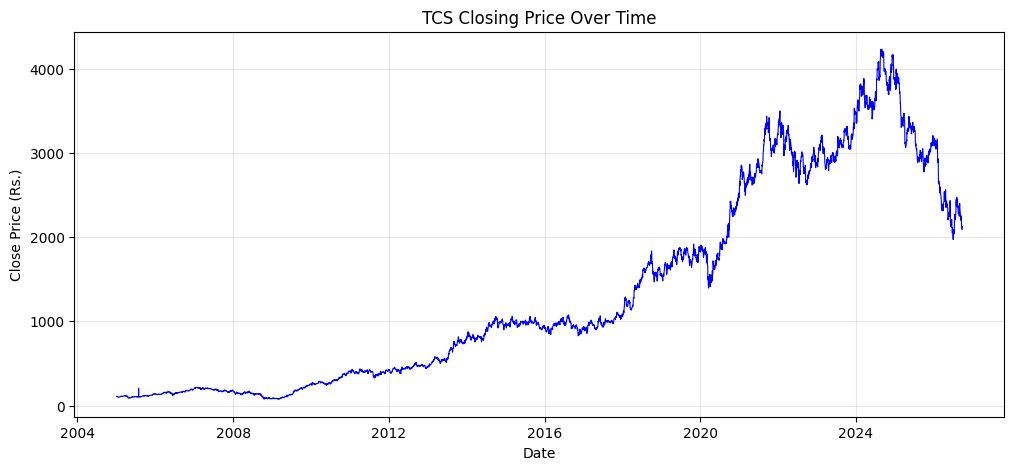

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Close'], color='blue', linewidth=0.8)
plt.xlabel('Date'); plt.ylabel('Close Price (Rs.)')
plt.title('TCS Closing Price Over Time')
plt.grid(True, alpha=0.3)
plt.show()

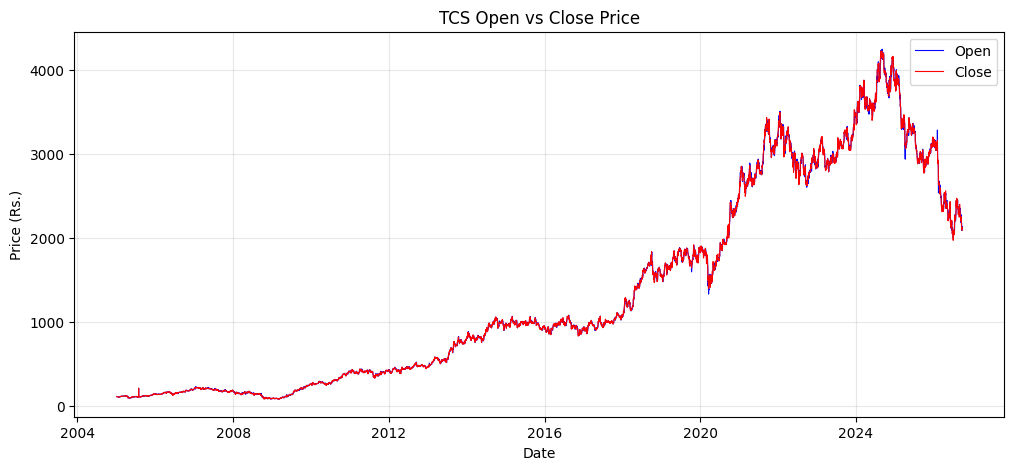

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Open'],  color='blue',   linewidth=0.8, label='Open')
plt.plot(df.index, df['Close'], color='red',    linewidth=0.8, label='Close')
plt.xlabel('Date'); plt.ylabel('Price (Rs.)')
plt.title('TCS Open vs Close Price')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

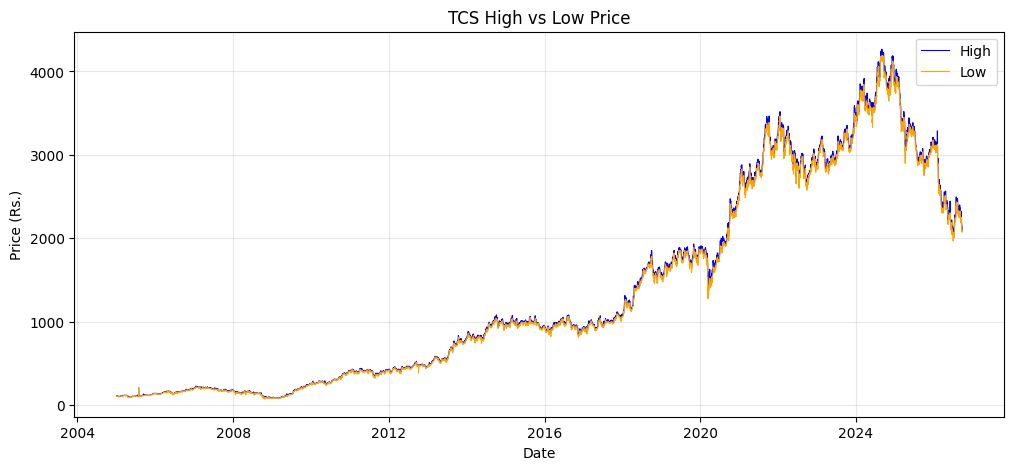

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['High'], label='High', color='blue',   linewidth=0.8)
plt.plot(df.index, df['Low'],  label='Low',  color='orange', linewidth=0.8)
plt.xlabel('Date'); plt.ylabel('Price (Rs.)')
plt.title('TCS High vs Low Price')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

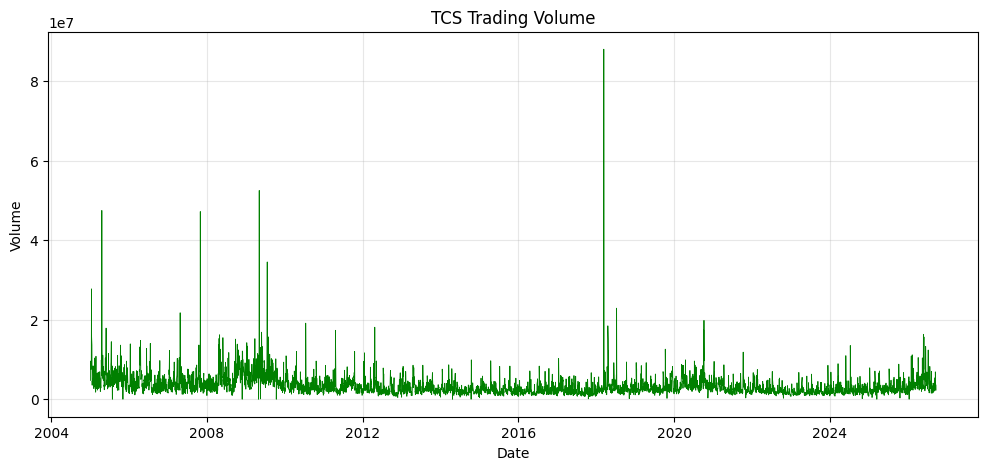

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Volume'], color='green', linewidth=0.6)
plt.xlabel('Date'); plt.ylabel('Volume')
plt.title('TCS Trading Volume')
plt.grid(True, alpha=0.3)
plt.show()

---
## Step 5: Create Target Variable — Next_Day_Close

In [ ]:
df['Next_Day_Close'] = df['Close'].shift(-1)
df.dropna(subset=['Next_Day_Close'], inplace=True)
print(f"Target created. Rows: {len(df)}")
df[['Close','Next_Day_Close']].head(3)

Target created. Rows: 5362


,Close,Next_Day_Close
Date,,
2005-01-03,108.272682,107.312592
2005-01-04,107.312592,106.011650
2005-01-05,106.011650,105.648438


---
## Step 7: Define Feature Set A — OHLCV Only (5 Features) + 80/20 Train-Test Split


In [ ]:
SET_A = ['Open', 'High', 'Low', 'Close', 'Volume']
X_A = df[SET_A].copy()
y   = df['Next_Day_Close']

split = int(len(X_A) * 0.80)
X_A_train, X_A_test = X_A.iloc[:split], X_A.iloc[split:]
y_train,   y_test   = y.iloc[:split],   y.iloc[split:]

print(f"Set A — Train:{X_A_train.shape}  Test:{X_A_test.shape}")
print(f"Features: {SET_A}")


In [ ]:
# ── EDA 2: Train vs Test Close stats + Volume==0 ────────────────────────────

# --- Train / Test describe for Close ---
close_train = X_A_train['Close']
close_test  = X_A_test['Close']

print('Close Price — TRAIN set')
display(close_train.describe().to_frame().T.round(2))

print('Close Price — TEST set')
display(close_test.describe().to_frame().T.round(2))

# --- Small comparison table ---
comp = pd.DataFrame({
    'Split' : ['Train', 'Test'],
    'Min (Rs)' : [round(close_train.min(), 2), round(close_test.min(), 2)],
    'Mean (Rs)': [round(close_train.mean(), 2), round(close_test.mean(), 2)],
    'Max (Rs)' : [round(close_train.max(), 2), round(close_test.max(), 2)],
})
pct_above = (close_test > close_train.max()).mean() * 100
print('\nTrain vs Test Close Summary')
display(comp)
print(f'% of Test rows where Close > Training Maximum ({round(close_train.max(),2)}): '
      f'{pct_above:.2f}%')

# --- Volume == 0 ---
vol_zero_full = (X_A['Volume'] == 0).sum()
vol_zero_train = (X_A_train['Volume'] == 0).sum()
vol_zero_test  = (X_A_test['Volume'] == 0).sum()
print(f'\nRows with Volume == 0: {vol_zero_full} total '
      f'({vol_zero_train} train, {vol_zero_test} test)')

Close Price — TRAIN set


,count,mean,std,min,25%,50%,75%,max
Close,4266.0,903.02,837.82,75.49,201.22,735.02,1155.77,3498.13


Close Price — TEST set


,count,mean,std,min,25%,50%,75%,max
Close,1067.0,3138.44,500.55,1971.79,2874.07,3079.28,3516.16,4230.71



Train vs Test Close Summary


,Split,Min (Rs),Mean (Rs),Max (Rs)
0,Train,75.49,903.02,3498.13
1,Test,1971.79,3138.44,4230.71


% of Test rows where Close > Training Maximum (3498.13): 25.40%

Rows with Volume == 0: 9 total (7 train, 2 test)


---
### Note: Feature Scales and Test-Period Price Regime

**Feature scale mismatch:**
The features used in Set B operate on very different numerical scales:

| Feature | Typical Range | Unit |
|:--------|:-------------|:----|
| RSI_14 | 0 – 100 | dimensionless |
| Daily_Return | ≈ −5 to +5 | % per day |
| Volume | 100,000 – 50,000,000 | shares/day |
| Close / Open / High / Low | 100 – 4,500 | INR |
| MACD | −20 to +20 | INR |

Because of this scale mismatch, **StandardScaler is applied for Ridge, Lasso, Elastic Net, SVR and KNN** 
(distance- or regularisation-based models are sensitive to feature magnitudes). 
Simple Linear Regression, Decision Tree, Random Forest, Gradient Boosting and XGBoost 
are scale-invariant and do not need scaling.

**Train → Test regime shift:**  
As seen in the table above, the **test period has a substantially higher price level** than 
the training period. Tree-based models cannot extrapolate beyond the training price range, 
which explains their high error on the test set when predicting price directly.  
This is why a *next-day return* formulation (predicting % change, then converting back to price) 
is explored later in the notebook.

## Step 8: Train vs Test Split — Visualization

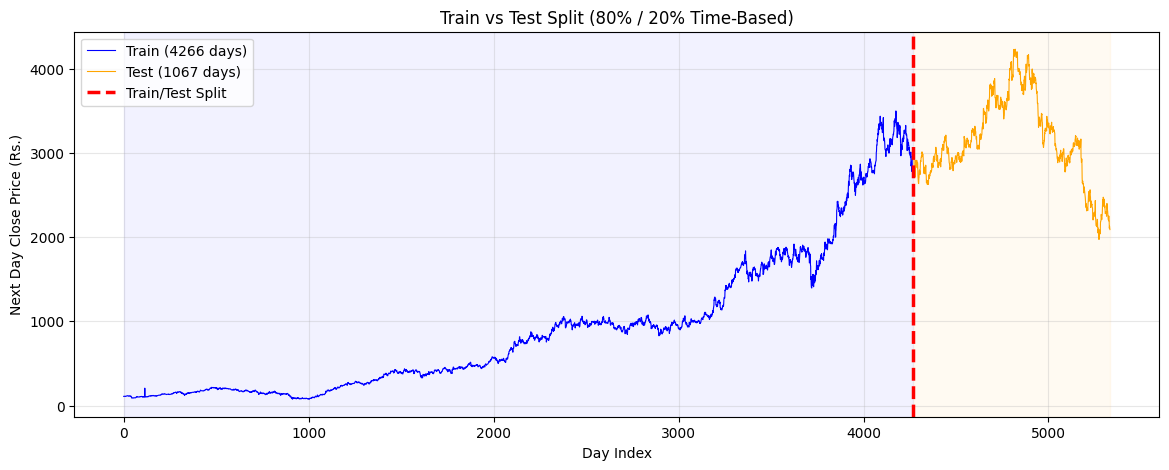

Train: 2005-02-15 to 2022-05-30
Test : 2022-05-31  to 2026-09-22


In [ ]:
n_tr = len(y_train); n_te = len(y_test)

plt.figure(figsize=(14, 5))
plt.plot(range(n_tr), y_train.values, color='blue', lw=0.8, label=f'Train ({n_tr} days)')
plt.plot(range(n_tr, n_tr+n_te), y_test.values, color='orange', lw=0.8, label=f'Test ({n_te} days)')
plt.axvline(n_tr, color='red', lw=2.5, linestyle='--', label='Train/Test Split')
plt.axvspan(0, n_tr, alpha=0.05, color='blue')
plt.axvspan(n_tr, n_tr+n_te, alpha=0.05, color='orange')
plt.title('Train vs Test Split (80% / 20% Time-Based)')
plt.xlabel('Day Index'); plt.ylabel('Next Day Close Price (Rs.)')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()
print(f"Train: {y_train.index[0].date()} to {y_train.index[-1].date()}")
print(f"Test : {y_test.index[0].date()}  to {y_test.index[-1].date()}")

## Step 9: Helper Functions

In [ ]:
def get_metrics(y_true, y_pred):
    y_true = np.array(y_true); y_pred = np.array(y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    da   = np.mean(np.sign(np.diff(y_true)) == np.sign(np.diff(y_pred))) * 100
    return {'MAE': mae, 'RMSE': rmse, 'R2': r2, 'MAPE': mape, 'Dir_Acc': da}

def print_metrics(metrics, name):
    print(f"{'='*45}")
    print(f"  Metrics: {name}")
    print(f"{'='*45}")
    print(f"  MAE           : Rs {metrics['MAE']:.2f}")
    print(f"  RMSE          : Rs {metrics['RMSE']:.2f}")
    print(f"  R2 Score      : {metrics['R2']:.6f}")
    print(f"  MAPE          : {metrics['MAPE']:.4f}%")
    print(f"  Dir. Accuracy : {metrics['Dir_Acc']:.2f}%")

# All results stored here for final comparison
all_results = []
print("Helper functions ready!")

Helper functions ready!


---
---
# Model 1: Simple Linear Regression
**Family:** Linear
**Structure:** OHLCV Only → train → metrics → graphs → overfit check → then OHLCV+Indicators → compare

## Model 1A: Simple Linear Regression — Set A (OHLCV Only, 1 features)

In [ ]:
# Simple LR uses only 1 feature: Close (baseline)
X_A_train_1 = X_A_train[['Close']]
X_A_test_1  = X_A_test[['Close']]
print("Feature: Close only (1 feature)")

Feature: Close only (1 feature)


In [ ]:
# Create and train the model
model_A_1 = LinearRegression()
model_A_1.fit(X_A_train_1, y_train)
print("Model trained successfully!")

Model trained successfully!


In [ ]:
# Predict on test set
y_pred_A_1 = model_A_1.predict(X_A_test_1)
print("First 5 Predictions:")
print(y_pred_A_1[:5])

First 5 Predictions:
[2954.473539   2946.43885868 3005.97129976 3021.03006715 3012.95240365]


In [ ]:
# Comparison table: Actual vs Predicted
comparison_A_1 = pd.DataFrame({
    'Date'                  : y_test.index,
    'Actual Next Day Close' : y_test.values,
    'Predicted Next Day Close': y_pred_A_1,
})
comparison_A_1['Difference'] = (comparison_A_1['Actual Next Day Close']
                                          - comparison_A_1['Predicted Next Day Close'])
comparison_A_1.head(10)

,Date,Actual Next Day Close,Predicted Next Day Close,Difference
0,2022-05-31,2945.086670,2954.473539,-9.386869
1,2022-06-01,3004.599121,2946.438859,58.160262
2,2022-06-02,3019.652832,3005.971300,13.681532
3,2022-06-03,3011.577881,3021.030067,-9.452186
4,2022-06-06,2951.669922,3012.952404,-61.282482
5,2022-06-07,2988.053467,2953.024322,35.029145
6,2022-06-08,3008.198486,2989.420088,18.778398
7,2022-06-09,2949.211670,3009.571874,-60.360204
8,2022-06-10,2826.061279,2950.565244,-124.503965
9,2022-06-13,2818.116943,2827.373488,-9.256545


In [ ]:
# Compute metrics
metrics_A_1 = get_metrics(y_test, y_pred_A_1)
print_metrics(metrics_A_1, "Simple Linear Regression — OHLCV Only")

  Metrics: Simple Linear Regression — OHLCV Only
  MAE           : Rs 31.14
  RMSE          : Rs 43.41
  R2 Score      : 0.992501
  MAPE          : 1.0133%
  Dir. Accuracy : 50.38%


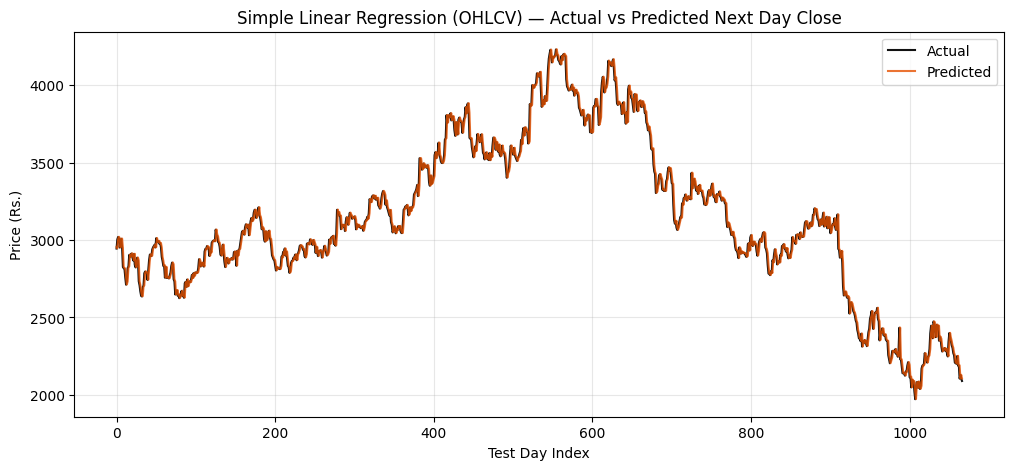

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(y_test.values, color='#111111', linewidth=1.5, label='Actual')
plt.plot(y_pred_A_1, color='#E65100', linewidth=1.5, label='Predicted', alpha=0.8)
plt.xlabel('Test Day Index'); plt.ylabel('Price (Rs.)')
plt.title('Simple Linear Regression (OHLCV) — Actual vs Predicted Next Day Close')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# ── Overfit / Underfitting Check — Simple LR — OHLCV Only (Set A) ─────────────────────────────
_y_tr_oc = model_A_1.predict(X_A_train_1)      # train predictions
_tr_m    = get_metrics(y_train, _y_tr_oc)
_te_m    = get_metrics(y_test,  y_pred_A_1)         # test predictions already computed

_r2_gap     = _tr_m['R2'] - _te_m['R2']
_mape_ratio = _te_m['MAPE'] / max(_tr_m['MAPE'], 1e-9)

if (_te_m['MAPE'] > 1.5 * _tr_m['MAPE']) or (_r2_gap > 0.05):
    _verdict = 'OVERFIT  ⚠️'
elif _tr_m['R2'] < 0.80:
    _verdict = 'UNDERFIT ⚠️'
else:
    _verdict = 'GOOD FIT ✅'

print("="*52)
print(f"  Overfit Check — Simple LR — OHLCV Only (Set A)")
print("="*52)
print(f"  Train MAPE : {_tr_m['MAPE']:.4f}%")
print(f"  Test  MAPE : {_te_m['MAPE']:.4f}%")
print(f"  MAPE Ratio : {_mape_ratio:.2f}x  (threshold: > 1.5x = OVERFIT)")
print(f"  Train R2   : {_tr_m['R2']:.6f}")
print(f"  Test  R2   : {_te_m['R2']:.6f}")
print(f"  R2 Gap     : {_r2_gap:.6f}  (threshold: > 0.05 = OVERFIT)")
print(f"  VERDICT    : {_verdict}")
print("="*52)

  Overfit Check — Simple LR — OHLCV Only (Set A)
  Train MAPE : 1.3927%
  Test  MAPE : 1.0133%
  MAPE Ratio : 0.73x  (threshold: > 1.5x = OVERFIT)
  Train R2   : 0.999479
  Test  R2   : 0.992501
  R2 Gap     : 0.006978  (threshold: > 0.05 = OVERFIT)
  VERDICT    : GOOD FIT ✅


### Why Scatter Plot? (Research Justification)

**Actual vs Predicted Scatter Plot:**
> Standard diagnostic tool in regression evaluation (James et al., 2013 — Introduction to Statistical Learning).
> Perfect model: all points on y = x diagonal.
> Points tightly around diagonal = accurate, unbiased model.
> Fan shape = heteroscedasticity (variance increases with price level).
>
> *Source: James, G. et al. (2013). An Introduction to Statistical Learning. Springer.*

### Why RSI and MACD? (Literature Basis — Tested Here)

**Indicators chosen based on published research:**

| Indicator | Source |
|-----------|--------|
| **RSI** | Wilder, J.W. (1978). *New Concepts in Technical Trading Systems.* |
| **MACD** | Appel, G. (1979). *The MACD Trading Method.* |
| **RSI + MACD in ML** | Mehtab, S., Sen, J., & Dutta, A. (2021). *Stock Price Prediction Using Machine Learning and LSTM-Based Deep Learning Models.* Springer. |

> **Result on TCS data:** Technical indicators (RSI, MACD, MAs) gave **no meaningful improvement**
> over raw OHLCV features for any of the 11 models tested.
> For linear models, MAPE slightly worsened with indicators added.
> For tree/KNN/SVR, the price-range extrapolation problem dominates — indicators do not fix it.

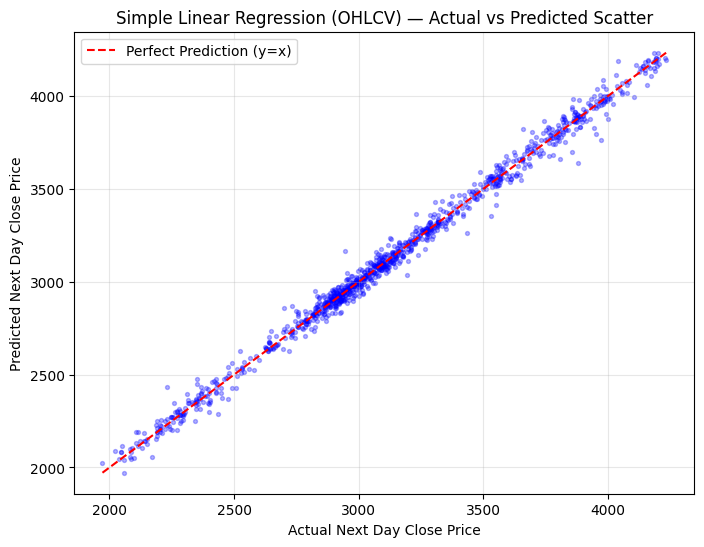

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test.values, y_pred_A_1, alpha=0.3, s=8, color='blue')
mn = min(y_test.min(), y_pred_A_1.min())
mx = max(y_test.max(), y_pred_A_1.max())
plt.plot([mn, mx], [mn, mx], 'r--', lw=1.5, label='Perfect Prediction (y=x)')
plt.xlabel('Actual Next Day Close Price')
plt.ylabel('Predicted Next Day Close Price')
plt.title('Simple Linear Regression (OHLCV) — Actual vs Predicted Scatter')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

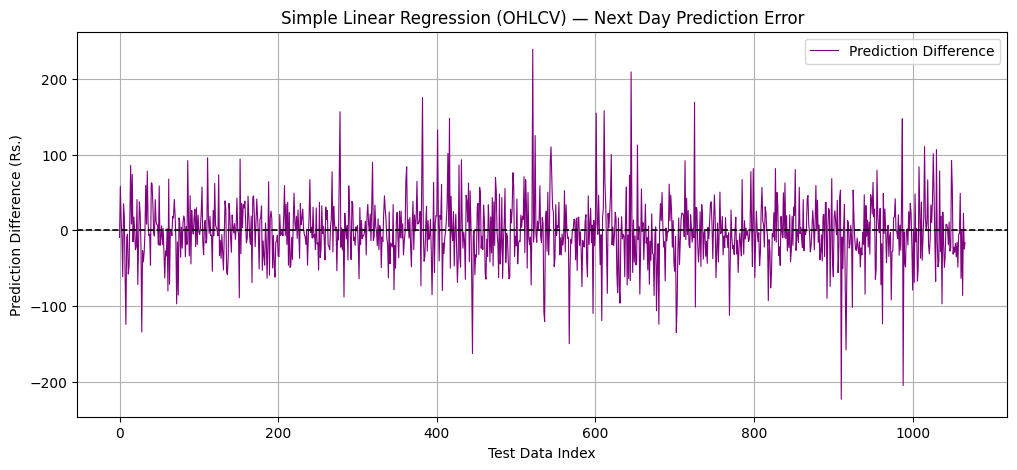

In [ ]:
residuals_A_1 = y_test.values - y_pred_A_1

plt.figure(figsize=(12, 5))
plt.plot(residuals_A_1, color='purple', linewidth=0.8, label='Prediction Difference')
plt.axhline(0, color='black', linestyle='--', linewidth=1.2)
plt.xlabel('Test Data Index'); plt.ylabel('Prediction Difference (Rs.)')
plt.title('Simple Linear Regression (OHLCV) — Next Day Prediction Error')
plt.legend(); plt.grid(True)
plt.show()

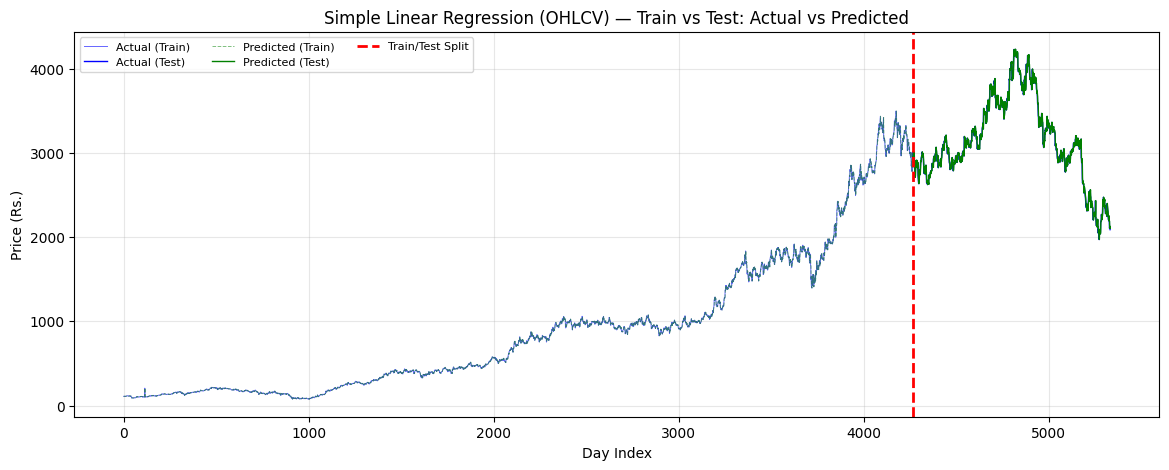

In [ ]:
# Train predictions (to show on split graph)
y_train_pred_A_1 = model_A_1.predict(X_A_train_1)

plt.figure(figsize=(14, 5))
plt.plot(range(n_tr), y_train.values, color='blue', lw=0.7, alpha=0.6, label='Actual (Train)')
plt.plot(range(n_tr, n_tr+n_te), y_test.values, color='blue', lw=1.0, label='Actual (Test)')
plt.plot(range(n_tr), y_train_pred_A_1, color='green', lw=0.7, alpha=0.5,
         linestyle='--', label='Predicted (Train)')
plt.plot(range(n_tr, n_tr+n_te), y_pred_A_1, color='green', lw=1.0, label='Predicted (Test)')
plt.axvline(n_tr, color='red', lw=2, linestyle='--', label='Train/Test Split')
plt.title('Simple Linear Regression (OHLCV) — Train vs Test: Actual vs Predicted')
plt.xlabel('Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(fontsize=8, ncol=3); plt.grid(True, alpha=0.3)
plt.show()

### Overfitting / Underfitting Check — Simple Linear Regression (OHLCV)

In [ ]:
tr_metrics_A = get_metrics(y_train, y_train_pred_A_1)
te_metrics_A = metrics_A_1

print(f"==================================================")
print(f"  Overfit Check: Simple Linear Regression — OHLCV Only")
print(f"==================================================")
print(f"  Train MAPE : {tr_metrics_A['MAPE']:.4f}%")
print(f"  Test  MAPE : {te_metrics_A['MAPE']:.4f}%")
print(f"  Gap        : {te_metrics_A['MAPE'] - tr_metrics_A['MAPE']:+.4f}%")
print(f"  Train R2   : {tr_metrics_A['R2']:.6f}")
print(f"  Test  R2   : {te_metrics_A['R2']:.6f}")

if te_metrics_A['MAPE'] > 1.5 * tr_metrics_A['MAPE']:
    verdict_A = 'OVERFITTING'
elif tr_metrics_A['R2'] < 0.80 and te_metrics_A['R2'] < 0.80:
    verdict_A = 'UNDERFITTING'
else:
    verdict_A = 'GOOD FIT'
print(f"  Verdict    : {verdict_A}")

  Overfit Check: Simple Linear Regression — OHLCV Only
  Train MAPE : 1.3927%
  Test  MAPE : 1.0133%
  Gap        : -0.3794%
  Train R2   : 0.999479
  Test  R2   : 0.992501
  Verdict    : GOOD FIT


---
---
# 💡 New Idea: Add Technical Indicators to Improve Accuracy

### After running all 11 models on OHLCV only, a key question arises:
> **Can we extract more signal from the data using Feature Engineering?**

Raw OHLCV captures prices and volume — but **not market behavior**.  
Technical Indicators capture: trend, momentum, volatility, and market strength.

| # | Indicator | Captures |
|---|-----------|---------|
| 1 | MA_7, MA_30 | Short & long-term trend |
| 2 | EMA_12, EMA_26 | Exponential trend (recent data weighted more) |
| 3 | MACD | Momentum crossover signal |
| 4 | RSI_14 | Overbought / Oversold market state |
| 5 | Daily Return | Day-over-day % change |
| 6 | Volatility | Market uncertainty level |
| 7 | Lag1 Close | Yesterday's close (autocorrelation) |

> **Hypothesis:** Adding these 9 features (Set B = 14 total) will improve all model metrics.  
> ↓ Let's compute them and re-run all 11 models!


---
## Step 6: Compute Technical Indicators
> All computed from past/current data only — **no future data leakage.**


In [ ]:
d = df.copy()
d['MA_7']         = d['Close'].rolling(7).mean()
d['MA_30']        = d['Close'].rolling(30).mean()
d['EMA_12']       = d['Close'].ewm(span=12, adjust=False).mean()
d['EMA_26']       = d['Close'].ewm(span=26, adjust=False).mean()
d['MACD']         = d['EMA_12'] - d['EMA_26']
delta = d['Close'].diff()
gain  = delta.where(delta > 0, 0).rolling(14).mean()
loss  = (-delta.where(delta < 0, 0)).rolling(14).mean()
d['RSI_14']       = 100 - (100 / (1 + gain / loss))
d['Daily_Return'] = d['Close'].pct_change() * 100
d['Volatility']   = d['Daily_Return'].rolling(7).std()
d['Lag1_Close']   = d['Close'].shift(1)
d['Next_Day_Close'] = d['Close'].shift(-1)
d.dropna(inplace=True)
print(f"Indicators ready. Rows: {len(d)}")


---
## Step 7B: Set B — OHLCV + Indicators (14 Features)
Same 80/20 split boundaries for **fair comparison** with Set A.


In [ ]:
SET_B = ['Open','High','Low','Close','Volume',
         'MA_7','MA_30','EMA_12','EMA_26','MACD',
         'RSI_14','Daily_Return','Volatility','Lag1_Close']

X_B = d[SET_B].copy()
y_B = d['Next_Day_Close']
split_B = int(len(X_B) * 0.80)
X_B_train, X_B_test = X_B.iloc[:split_B], X_B.iloc[split_B:]
y_train_B, y_test_B = y_B.iloc[:split_B], y_B.iloc[split_B:]
print(f"Set B — Train:{X_B_train.shape}  Test:{X_B_test.shape}")
print(f"14 Features: {SET_B}")


## Model 1B: Simple Linear Regression — Set B (OHLCV + Indicators, 1 features)

In [ ]:
# Simple LR: still only Close (definition doesn't change)
X_B_train_1 = X_B_train[['Close']]
X_B_test_1  = X_B_test[['Close']]
print("Feature: Close only (baseline stays same)")

Feature: Close only (baseline stays same)


In [ ]:
# Create and train model on Set B
model_B_1 = LinearRegression()
model_B_1.fit(X_B_train_1, y_train)
print("Model trained on OHLCV + Indicators!")

Model trained on OHLCV + Indicators!


In [ ]:
y_pred_B_1 = model_B_1.predict(X_B_test_1)
print("First 5 Predictions:")
print(y_pred_B_1[:5])

First 5 Predictions:
[2954.473539   2946.43885868 3005.97129976 3021.03006715 3012.95240365]


In [ ]:
comparison_B_1 = pd.DataFrame({
    'Date'                    : y_test.index,
    'Actual Next Day Close'   : y_test.values,
    'Predicted Next Day Close': y_pred_B_1,
})
comparison_B_1['Difference'] = (comparison_B_1['Actual Next Day Close']
                                          - comparison_B_1['Predicted Next Day Close'])
comparison_B_1.head(10)

,Date,Actual Next Day Close,Predicted Next Day Close,Difference
0,2022-05-31,2945.086670,2954.473539,-9.386869
1,2022-06-01,3004.599121,2946.438859,58.160262
2,2022-06-02,3019.652832,3005.971300,13.681532
3,2022-06-03,3011.577881,3021.030067,-9.452186
4,2022-06-06,2951.669922,3012.952404,-61.282482
5,2022-06-07,2988.053467,2953.024322,35.029145
6,2022-06-08,3008.198486,2989.420088,18.778398
7,2022-06-09,2949.211670,3009.571874,-60.360204
8,2022-06-10,2826.061279,2950.565244,-124.503965
9,2022-06-13,2818.116943,2827.373488,-9.256545


In [ ]:
metrics_B_1 = get_metrics(y_test, y_pred_B_1)
print_metrics(metrics_B_1, "Simple Linear Regression — OHLCV + Indicators")

  Metrics: Simple Linear Regression — OHLCV + Indicators
  MAE           : Rs 31.14
  RMSE          : Rs 43.41
  R2 Score      : 0.992501
  MAPE          : 1.0133%
  Dir. Accuracy : 50.38%


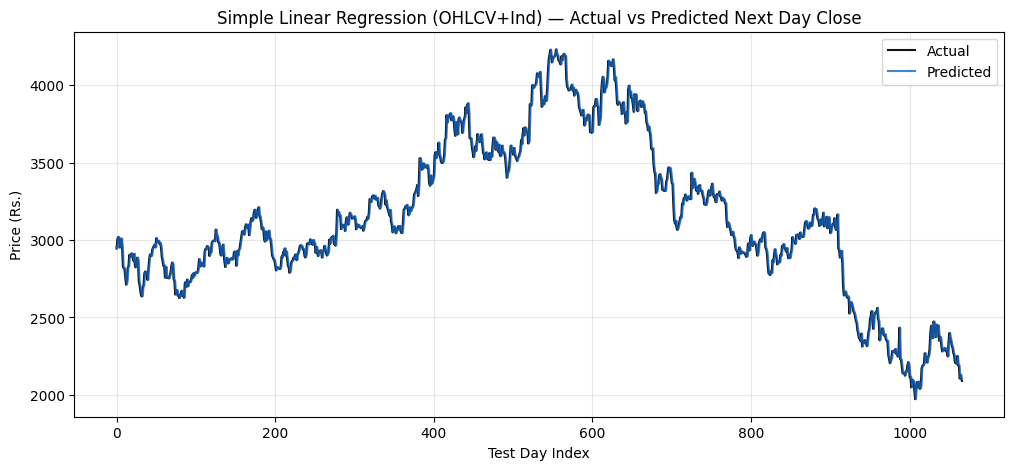

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(y_test.values, color='#111111', linewidth=1.5, label='Actual')
plt.plot(y_pred_B_1, color='#1565C0', linewidth=1.5, label='Predicted', alpha=0.8)
plt.xlabel('Test Day Index'); plt.ylabel('Price (Rs.)')
plt.title('Simple Linear Regression (OHLCV+Ind) — Actual vs Predicted Next Day Close')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# ── Overfit / Underfitting Check — Simple LR — OHLCV + Indicators (Set B) ─────────────────────────────
_y_tr_oc = model_B_1.predict(X_B_train_1)      # train predictions
_tr_m    = get_metrics(y_train, _y_tr_oc)
_te_m    = get_metrics(y_test,  y_pred_B_1)         # test predictions already computed

_r2_gap     = _tr_m['R2'] - _te_m['R2']
_mape_ratio = _te_m['MAPE'] / max(_tr_m['MAPE'], 1e-9)

if (_te_m['MAPE'] > 1.5 * _tr_m['MAPE']) or (_r2_gap > 0.05):
    _verdict = 'OVERFIT  ⚠️'
elif _tr_m['R2'] < 0.80:
    _verdict = 'UNDERFIT ⚠️'
else:
    _verdict = 'GOOD FIT ✅'

print("="*52)
print(f"  Overfit Check — Simple LR — OHLCV + Indicators (Set B)")
print("="*52)
print(f"  Train MAPE : {_tr_m['MAPE']:.4f}%")
print(f"  Test  MAPE : {_te_m['MAPE']:.4f}%")
print(f"  MAPE Ratio : {_mape_ratio:.2f}x  (threshold: > 1.5x = OVERFIT)")
print(f"  Train R2   : {_tr_m['R2']:.6f}")
print(f"  Test  R2   : {_te_m['R2']:.6f}")
print(f"  R2 Gap     : {_r2_gap:.6f}  (threshold: > 0.05 = OVERFIT)")
print(f"  VERDICT    : {_verdict}")
print("="*52)

  Overfit Check — Simple LR — OHLCV + Indicators (Set B)
  Train MAPE : 1.3927%
  Test  MAPE : 1.0133%
  MAPE Ratio : 0.73x  (threshold: > 1.5x = OVERFIT)
  Train R2   : 0.999479
  Test  R2   : 0.992501
  R2 Gap     : 0.006978  (threshold: > 0.05 = OVERFIT)
  VERDICT    : GOOD FIT ✅


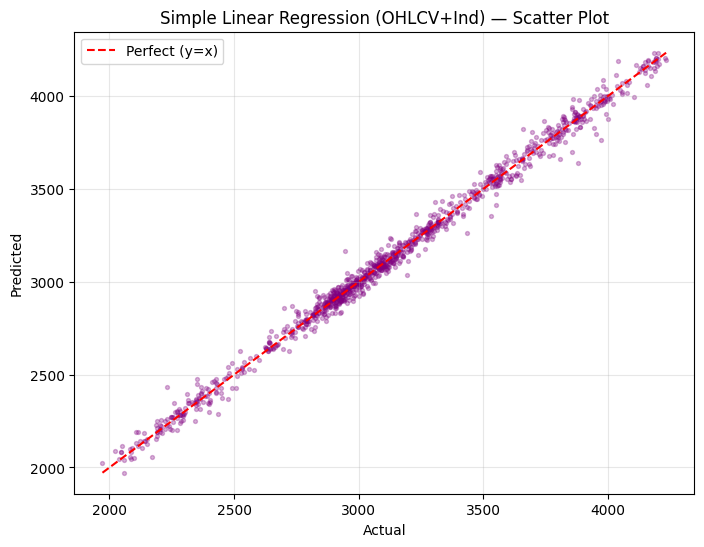

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test.values, y_pred_B_1, alpha=0.3, s=8, color='purple')
mn = min(y_test.min(), y_pred_B_1.min())
mx = max(y_test.max(), y_pred_B_1.max())
plt.plot([mn, mx], [mn, mx], 'r--', lw=1.5, label='Perfect (y=x)')
plt.xlabel('Actual'); plt.ylabel('Predicted')
plt.title('Simple Linear Regression (OHLCV+Ind) — Scatter Plot')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

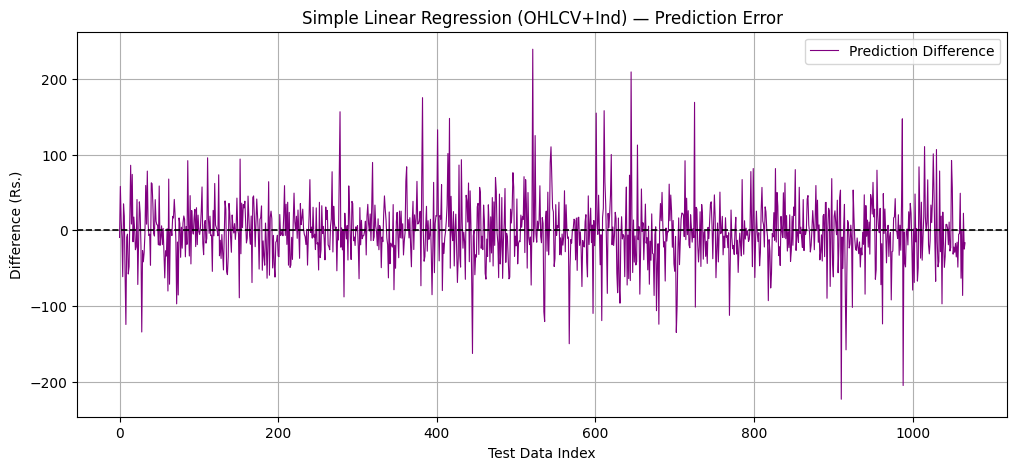

In [ ]:
residuals_B_1 = y_test.values - y_pred_B_1
plt.figure(figsize=(12, 5))
plt.plot(residuals_B_1, color='purple', linewidth=0.8, label='Prediction Difference')
plt.axhline(0, color='black', linestyle='--', linewidth=1.2)
plt.xlabel('Test Data Index'); plt.ylabel('Difference (Rs.)')
plt.title('Simple Linear Regression (OHLCV+Ind) — Prediction Error')
plt.legend(); plt.grid(True)
plt.show()

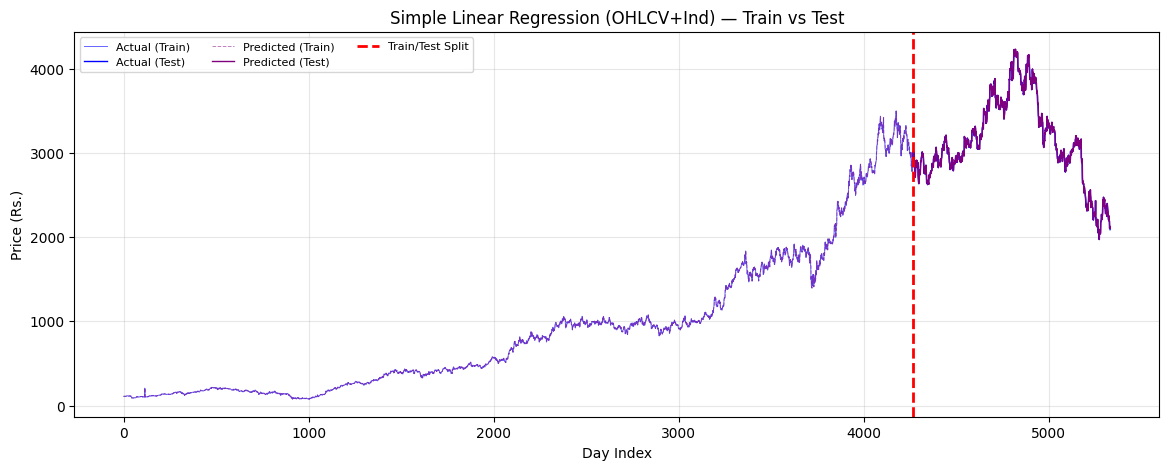

In [ ]:
y_train_pred_B_1 = model_B_1.predict(X_B_train_1)

plt.figure(figsize=(14, 5))
plt.plot(range(n_tr), y_train.values, color='blue', lw=0.7, alpha=0.6, label='Actual (Train)')
plt.plot(range(n_tr, n_tr+n_te), y_test.values, color='blue', lw=1.0, label='Actual (Test)')
plt.plot(range(n_tr), y_train_pred_B_1, color='purple', lw=0.7,
         alpha=0.5, linestyle='--', label='Predicted (Train)')
plt.plot(range(n_tr, n_tr+n_te), y_pred_B_1, color='purple', lw=1.0, label='Predicted (Test)')
plt.axvline(n_tr, color='red', lw=2, linestyle='--', label='Train/Test Split')
plt.title('Simple Linear Regression (OHLCV+Ind) — Train vs Test')
plt.xlabel('Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(fontsize=8, ncol=3); plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
tr_metrics_B = get_metrics(y_train, y_train_pred_B_1)
te_metrics_B = metrics_B_1

print(f"==================================================")
print(f"  Overfit Check: Simple Linear Regression — OHLCV + Indicators")
print(f"==================================================")
print(f"  Train MAPE : {tr_metrics_B['MAPE']:.4f}%")
print(f"  Test  MAPE : {te_metrics_B['MAPE']:.4f}%")
print(f"  Gap        : {te_metrics_B['MAPE'] - tr_metrics_B['MAPE']:+.4f}%")
print(f"  Train R2   : {tr_metrics_B['R2']:.6f}")
print(f"  Test  R2   : {te_metrics_B['R2']:.6f}")

if te_metrics_B['MAPE'] > 1.5 * tr_metrics_B['MAPE']:
    verdict_B = 'OVERFITTING'
elif tr_metrics_B['R2'] < 0.80 and te_metrics_B['R2'] < 0.80:
    verdict_B = 'UNDERFITTING'
else:
    verdict_B = 'GOOD FIT'
print(f"  Verdict    : {verdict_B}")

  Overfit Check: Simple Linear Regression — OHLCV + Indicators
  Train MAPE : 1.3927%
  Test  MAPE : 1.0133%
  Gap        : -0.3794%
  Train R2   : 0.999479
  Test  R2   : 0.992501
  Verdict    : GOOD FIT


## Model 1C: Compare OHLCV vs OHLCV+Indicators — Simple Linear Regression

In [ ]:
# ── Combined Predictions Table: Actual vs OHLCV (Set A) vs OHLCV+Indicators (Set B) ──
comparison_comb_1 = pd.DataFrame({
    'Date'                      : y_test.index,
    'Actual Next Day Close'     : y_test.values.round(2),
    'Pred (OHLCV Only)'         : y_pred_A_1.round(2),
    'Diff (OHLCV Only)'         : (y_test.values - y_pred_A_1).round(2),
    'Pred (OHLCV+Indicators)'   : y_pred_B_1.round(2),
    'Diff (OHLCV+Ind)'          : (y_test.values - y_pred_B_1).round(2),
})
print("Combined Predictions Comparison (Set A vs Set B) — Model 1 (Simple Linear Regression):")
display(comparison_comb_1.head(10))

# ── Set B Full Feature Table: OHLCV + All 9 Technical Indicators (14 Features) ──
print("\nSet B Features (OHLCV + All Indicators) — Test Set First 10 Days:")
display(X_B_test.head(10).round(2))

# ── Side-by-Side Metric Comparison Table ──
comp_1 = pd.DataFrame({
    'Metric'          : ['MAE (Rs.)','RMSE (Rs.)','R2 Score','MAPE (%)','Dir. Acc (%)'],
    'OHLCV Only'      : [round(metrics_A_1[k],4) for k in ['MAE','RMSE','R2','MAPE','Dir_Acc']],
    'OHLCV+Indicators': [round(metrics_B_1[k],4) for k in ['MAE','RMSE','R2','MAPE','Dir_Acc']],
})
comp_1['Improvement'] = comp_1['OHLCV Only'] - comp_1['OHLCV+Indicators']
print("\nEvaluation Metrics Comparison: Simple Linear Regression")
display(comp_1)


Combined Predictions Comparison (Set A vs Set B) — Model 1 (Simple Linear Regression):


,Date,Actual Next Day Close,Pred (OHLCV Only),Diff (OHLCV Only),Pred (OHLCV+Indicators),Diff (OHLCV+Ind)
0,2022-05-31,2945.09,2954.47,-9.39,2954.47,-9.39
1,2022-06-01,3004.60,2946.44,58.16,2946.44,58.16
2,2022-06-02,3019.65,3005.97,13.68,3005.97,13.68
3,2022-06-03,3011.58,3021.03,-9.45,3021.03,-9.45
4,2022-06-06,2951.67,3012.95,-61.28,3012.95,-61.28
5,2022-06-07,2988.05,2953.02,35.03,2953.02,35.03
6,2022-06-08,3008.20,2989.42,18.78,2989.42,18.78
7,2022-06-09,2949.21,3009.57,-60.36,3009.57,-60.36
8,2022-06-10,2826.06,2950.57,-124.50,2950.57,-124.50
9,2022-06-13,2818.12,2827.37,-9.26,2827.37,-9.26



Set B Features (OHLCV + All Indicators) — Test Set First 10 Days:


,Open,High,Low,Close,Volume,MA_7,MA_30,EMA_12,EMA_26,MACD,RSI_14,Volatility,Daily_Return,Lag1_Close
Date,,,,,,,,,,,,,,
2022-05-31,2944.17,2969.84,2918.58,2953.12,4840965,2879.21,2996.18,2915.49,2971.56,-56.07,48.28,2.10,-0.32,2962.69
2022-06-01,2973.88,2973.88,2931.79,2945.09,1493835,2886.19,2993.44,2920.04,2969.59,-49.55,47.89,2.11,-0.27,2953.12
2022-06-02,2944.91,3012.50,2937.27,3004.60,2657939,2905.88,2990.23,2933.05,2972.19,-39.14,51.97,2.11,2.02,2945.09
2022-06-03,3036.55,3052.26,3011.80,3019.65,1913622,2940.05,2985.42,2946.37,2975.70,-29.33,55.61,1.38,0.50,3004.60
2022-06-06,3000.21,3030.93,2964.35,3011.58,1084210,2965.63,2980.81,2956.40,2978.36,-21.96,50.17,1.44,-0.27,3019.65
2022-06-07,2985.33,3000.96,2945.79,2951.67,2308256,2978.34,2976.08,2955.68,2976.38,-20.71,45.89,1.79,-1.99,3011.58
2022-06-08,2966.99,2996.66,2937.45,2988.05,2185707,2981.97,2972.62,2960.66,2977.25,-16.59,63.17,1.29,1.23,2951.67
2022-06-09,2971.24,3016.89,2943.24,3008.20,1279197,2989.83,2969.39,2967.97,2979.54,-11.57,62.70,1.28,0.67,2988.05
2022-06-10,2968.61,2978.27,2942.28,2949.21,1527582,2990.42,2963.53,2965.09,2977.29,-12.21,54.62,1.54,-1.96,3008.20



Evaluation Metrics Comparison: Simple Linear Regression


,Metric,OHLCV Only,OHLCV+Indicators,Improvement
0,MAE (Rs.),31.1390,31.1390,0.0
1,RMSE (Rs.),43.4116,43.4116,0.0
2,R2 Score,0.9925,0.9925,0.0
3,MAPE (%),1.0133,1.0133,0.0
4,Dir. Acc (%),50.3752,50.3752,0.0


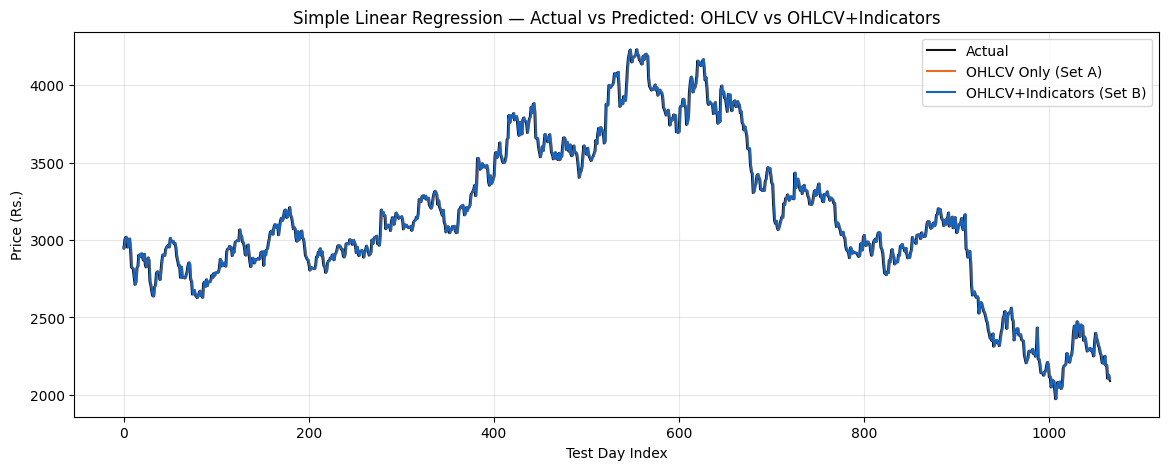

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(y_test.values,        color='#111111', lw=1.5, label='Actual')
plt.plot(y_pred_A_1, color='#E65100', lw=1.5, label='OHLCV Only (Set A)',       alpha=0.85)
plt.plot(y_pred_B_1, color='#1565C0', lw=1.5, label='OHLCV+Indicators (Set B)', )
plt.xlabel('Test Day Index'); plt.ylabel('Price (Rs.)')
plt.title('Simple Linear Regression — Actual vs Predicted: OHLCV vs OHLCV+Indicators')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Store results for final comparison
all_results.append({
    'Model': 'Simple Linear Regression', 'Set': 'OHLCV Only',
    'MAPE': metrics_A_1['MAPE'], 'R2': metrics_A_1['R2'],
    'MAE': metrics_A_1['MAE'],   'Dir_Acc': metrics_A_1['Dir_Acc'],
})
all_results.append({
    'Model': 'Simple Linear Regression', 'Set': 'OHLCV+Indicators',
    'MAPE': metrics_B_1['MAPE'], 'R2': metrics_B_1['R2'],
    'MAE': metrics_B_1['MAE'],   'Dir_Acc': metrics_B_1['Dir_Acc'],
})
print(f"Simple Linear Regression done! MAPE: A={metrics_A_1['MAPE']:.4f}%  B={metrics_B_1['MAPE']:.4f}%")

Simple Linear Regression done! MAPE: A=1.0133%  B=1.0133%


---
---
# Model 2: Multiple Linear Regression
**Family:** Linear
**Structure:** OHLCV Only → train → metrics → graphs → overfit check → then OHLCV+Indicators → compare

## Model 2A: Multiple Linear Regression — Set A (OHLCV Only, 5 features)

In [ ]:
# Features: Open, High, Low, Close, Volume (5 OHLCV columns)
X_A_train_2 = X_A_train
X_A_test_2  = X_A_test
print(f"Features: {X_A_train_2.shape[1]} OHLCV columns")

Features: 5 OHLCV columns


In [ ]:
# Create and train the model
model_A_2 = LinearRegression()
model_A_2.fit(X_A_train_2, y_train)
print("Model trained successfully!")

Model trained successfully!


In [ ]:
# Predict on test set
y_pred_A_2 = model_A_2.predict(X_A_test_2)
print("First 5 Predictions:")
print(y_pred_A_2[:5])

First 5 Predictions:
[2953.60580472 2945.77229977 3005.06852031 3021.86413671 3011.45833212]


In [ ]:
# Comparison table: Actual vs Predicted
comparison_A_2 = pd.DataFrame({
    'Date'                  : y_test.index,
    'Actual Next Day Close' : y_test.values,
    'Predicted Next Day Close': y_pred_A_2,
})
comparison_A_2['Difference'] = (comparison_A_2['Actual Next Day Close']
                                          - comparison_A_2['Predicted Next Day Close'])
comparison_A_2.head(10)

,Date,Actual Next Day Close,Predicted Next Day Close,Difference
0,2022-05-31,2945.086670,2953.605805,-8.519135
1,2022-06-01,3004.599121,2945.772300,58.826821
2,2022-06-02,3019.652832,3005.068520,14.584312
3,2022-06-03,3011.577881,3021.864137,-10.286256
4,2022-06-06,2951.669922,3011.458332,-59.788410
5,2022-06-07,2988.053467,2954.407420,33.646047
6,2022-06-08,3008.198486,2987.367611,20.830875
7,2022-06-09,2949.211670,3007.446812,-58.235142
8,2022-06-10,2826.061279,2951.000090,-124.938811
9,2022-06-13,2818.116943,2826.956463,-8.839520


In [ ]:
# Compute metrics
metrics_A_2 = get_metrics(y_test, y_pred_A_2)
print_metrics(metrics_A_2, "Multiple Linear Regression — OHLCV Only")

  Metrics: Multiple Linear Regression — OHLCV Only
  MAE           : Rs 31.17
  RMSE          : Rs 43.43
  R2 Score      : 0.992495
  MAPE          : 1.0144%
  Dir. Accuracy : 50.19%


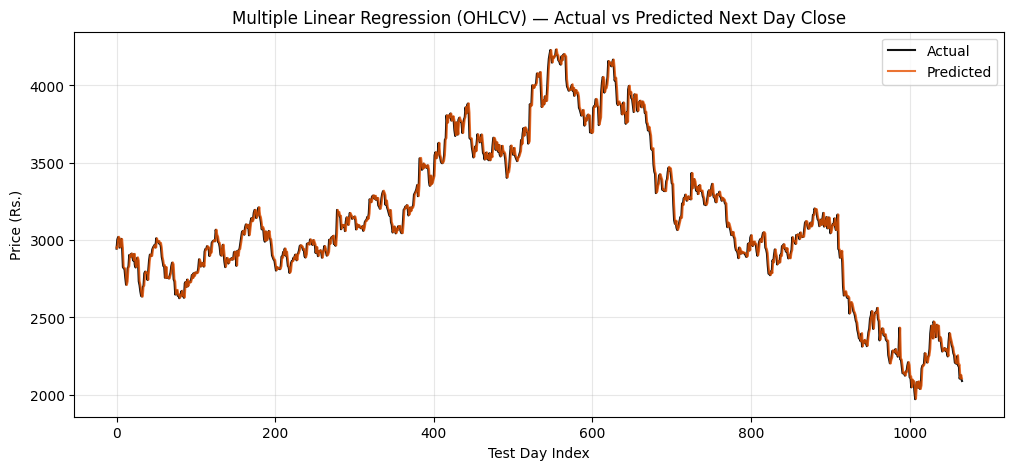

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(y_test.values, color='#111111', linewidth=1.5, label='Actual')
plt.plot(y_pred_A_2, color='#E65100', linewidth=1.5, label='Predicted', alpha=0.8)
plt.xlabel('Test Day Index'); plt.ylabel('Price (Rs.)')
plt.title('Multiple Linear Regression (OHLCV) — Actual vs Predicted Next Day Close')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# ── Overfit / Underfitting Check — Multiple LR — OHLCV Only (Set A) ─────────────────────────────
_y_tr_oc = model_A_2.predict(X_A_train_2)      # train predictions
_tr_m    = get_metrics(y_train, _y_tr_oc)
_te_m    = get_metrics(y_test,  y_pred_A_2)         # test predictions already computed

_r2_gap     = _tr_m['R2'] - _te_m['R2']
_mape_ratio = _te_m['MAPE'] / max(_tr_m['MAPE'], 1e-9)

if (_te_m['MAPE'] > 1.5 * _tr_m['MAPE']) or (_r2_gap > 0.05):
    _verdict = 'OVERFIT  ⚠️'
elif _tr_m['R2'] < 0.80:
    _verdict = 'UNDERFIT ⚠️'
else:
    _verdict = 'GOOD FIT ✅'

print("="*52)
print(f"  Overfit Check — Multiple LR — OHLCV Only (Set A)")
print("="*52)
print(f"  Train MAPE : {_tr_m['MAPE']:.4f}%")
print(f"  Test  MAPE : {_te_m['MAPE']:.4f}%")
print(f"  MAPE Ratio : {_mape_ratio:.2f}x  (threshold: > 1.5x = OVERFIT)")
print(f"  Train R2   : {_tr_m['R2']:.6f}")
print(f"  Test  R2   : {_te_m['R2']:.6f}")
print(f"  R2 Gap     : {_r2_gap:.6f}  (threshold: > 0.05 = OVERFIT)")
print(f"  VERDICT    : {_verdict}")
print("="*52)

  Overfit Check — Multiple LR — OHLCV Only (Set A)
  Train MAPE : 1.3944%
  Test  MAPE : 1.0144%
  MAPE Ratio : 0.73x  (threshold: > 1.5x = OVERFIT)
  Train R2   : 0.999480
  Test  R2   : 0.992495
  R2 Gap     : 0.006984  (threshold: > 0.05 = OVERFIT)
  VERDICT    : GOOD FIT ✅


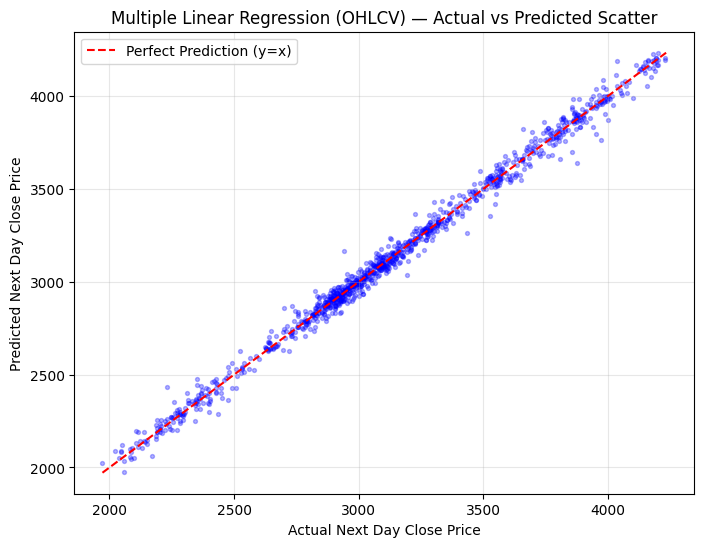

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test.values, y_pred_A_2, alpha=0.3, s=8, color='blue')
mn = min(y_test.min(), y_pred_A_2.min())
mx = max(y_test.max(), y_pred_A_2.max())
plt.plot([mn, mx], [mn, mx], 'r--', lw=1.5, label='Perfect Prediction (y=x)')
plt.xlabel('Actual Next Day Close Price')
plt.ylabel('Predicted Next Day Close Price')
plt.title('Multiple Linear Regression (OHLCV) — Actual vs Predicted Scatter')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

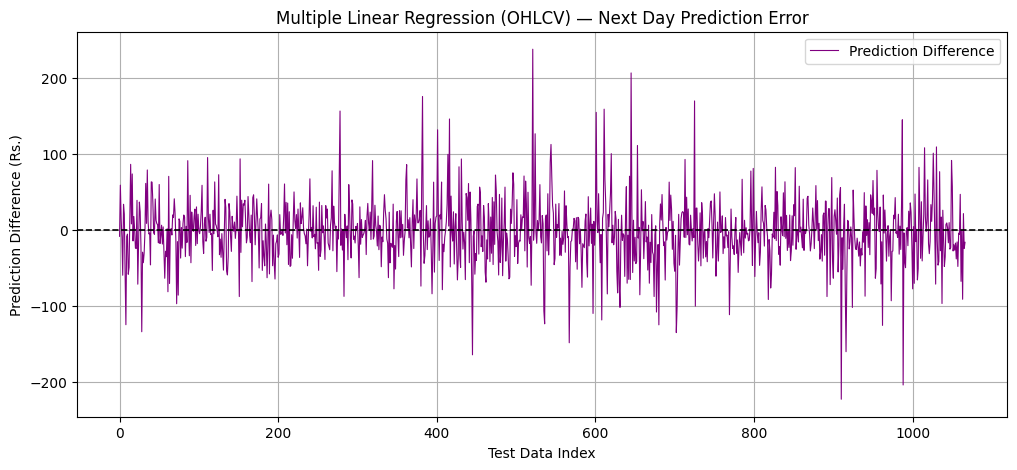

In [ ]:
residuals_A_2 = y_test.values - y_pred_A_2

plt.figure(figsize=(12, 5))
plt.plot(residuals_A_2, color='purple', linewidth=0.8, label='Prediction Difference')
plt.axhline(0, color='black', linestyle='--', linewidth=1.2)
plt.xlabel('Test Data Index'); plt.ylabel('Prediction Difference (Rs.)')
plt.title('Multiple Linear Regression (OHLCV) — Next Day Prediction Error')
plt.legend(); plt.grid(True)
plt.show()

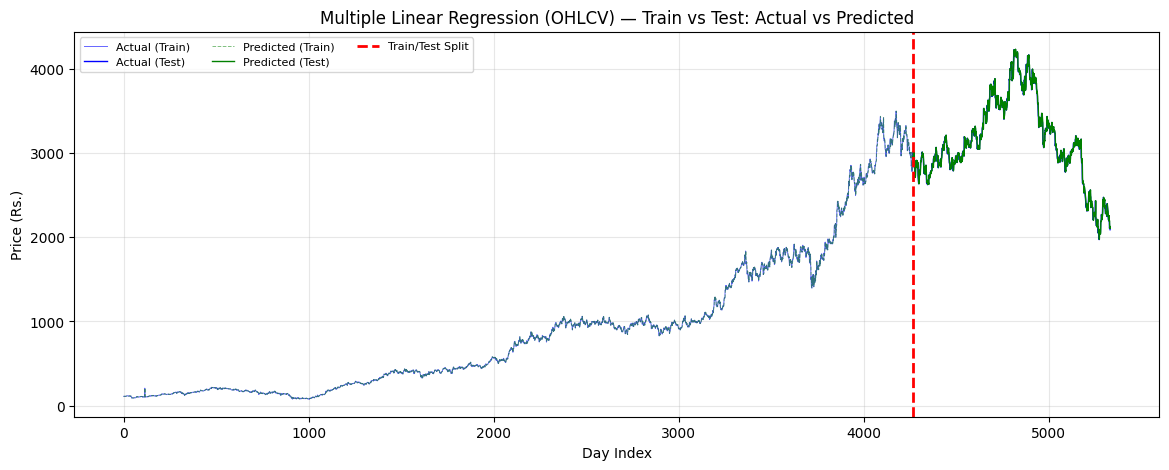

In [ ]:
# Train predictions (to show on split graph)
y_train_pred_A_2 = model_A_2.predict(X_A_train_2)

plt.figure(figsize=(14, 5))
plt.plot(range(n_tr), y_train.values, color='blue', lw=0.7, alpha=0.6, label='Actual (Train)')
plt.plot(range(n_tr, n_tr+n_te), y_test.values, color='blue', lw=1.0, label='Actual (Test)')
plt.plot(range(n_tr), y_train_pred_A_2, color='green', lw=0.7, alpha=0.5,
         linestyle='--', label='Predicted (Train)')
plt.plot(range(n_tr, n_tr+n_te), y_pred_A_2, color='green', lw=1.0, label='Predicted (Test)')
plt.axvline(n_tr, color='red', lw=2, linestyle='--', label='Train/Test Split')
plt.title('Multiple Linear Regression (OHLCV) — Train vs Test: Actual vs Predicted')
plt.xlabel('Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(fontsize=8, ncol=3); plt.grid(True, alpha=0.3)
plt.show()

### Overfitting / Underfitting Check — Multiple Linear Regression (OHLCV)

In [ ]:
tr_metrics_A = get_metrics(y_train, y_train_pred_A_2)
te_metrics_A = metrics_A_2

print(f"==================================================")
print(f"  Overfit Check: Multiple Linear Regression — OHLCV Only")
print(f"==================================================")
print(f"  Train MAPE : {tr_metrics_A['MAPE']:.4f}%")
print(f"  Test  MAPE : {te_metrics_A['MAPE']:.4f}%")
print(f"  Gap        : {te_metrics_A['MAPE'] - tr_metrics_A['MAPE']:+.4f}%")
print(f"  Train R2   : {tr_metrics_A['R2']:.6f}")
print(f"  Test  R2   : {te_metrics_A['R2']:.6f}")

if te_metrics_A['MAPE'] > 1.5 * tr_metrics_A['MAPE']:
    verdict_A = 'OVERFITTING'
elif tr_metrics_A['R2'] < 0.80 and te_metrics_A['R2'] < 0.80:
    verdict_A = 'UNDERFITTING'
else:
    verdict_A = 'GOOD FIT'
print(f"  Verdict    : {verdict_A}")

  Overfit Check: Multiple Linear Regression — OHLCV Only
  Train MAPE : 1.3944%
  Test  MAPE : 1.0144%
  Gap        : -0.3800%
  Train R2   : 0.999480
  Test  R2   : 0.992495
  Verdict    : GOOD FIT


## Model 2B: Multiple Linear Regression — Set B (OHLCV + Indicators, 14 features)

In [ ]:
# Features: OHLCV + 9 Technical Indicators (14 total)
X_B_train_2 = X_B_train
X_B_test_2  = X_B_test
print(f"Features: {X_B_train_2.shape[1]} columns (OHLCV + indicators)")

Features: 14 columns (OHLCV + indicators)


In [ ]:
# Create and train model on Set B
model_B_2 = LinearRegression()
model_B_2.fit(X_B_train_2, y_train)
print("Model trained on OHLCV + Indicators!")

Model trained on OHLCV + Indicators!


In [ ]:
y_pred_B_2 = model_B_2.predict(X_B_test_2)
print("First 5 Predictions:")
print(y_pred_B_2[:5])

First 5 Predictions:
[2955.7281267  2947.23381521 3007.46521753 3023.9279277  3013.98470939]


In [ ]:
comparison_B_2 = pd.DataFrame({
    'Date'                    : y_test.index,
    'Actual Next Day Close'   : y_test.values,
    'Predicted Next Day Close': y_pred_B_2,
})
comparison_B_2['Difference'] = (comparison_B_2['Actual Next Day Close']
                                          - comparison_B_2['Predicted Next Day Close'])
comparison_B_2.head(10)

,Date,Actual Next Day Close,Predicted Next Day Close,Difference
0,2022-05-31,2945.086670,2955.728127,-10.641457
1,2022-06-01,3004.599121,2947.233815,57.365306
2,2022-06-02,3019.652832,3007.465218,12.187615
3,2022-06-03,3011.577881,3023.927928,-12.350047
4,2022-06-06,2951.669922,3013.984709,-62.314788
5,2022-06-07,2988.053467,2958.224120,29.829346
6,2022-06-08,3008.198486,2993.439149,14.759337
7,2022-06-09,2949.211670,3012.707894,-63.496225
8,2022-06-10,2826.061279,2956.579982,-130.518702
9,2022-06-13,2818.116943,2833.401478,-15.284535


In [ ]:
metrics_B_2 = get_metrics(y_test, y_pred_B_2)
print_metrics(metrics_B_2, "Multiple Linear Regression — OHLCV + Indicators")

  Metrics: Multiple Linear Regression — OHLCV + Indicators
  MAE           : Rs 31.42
  RMSE          : Rs 43.68
  R2 Score      : 0.992408
  MAPE          : 1.0235%
  Dir. Accuracy : 50.09%


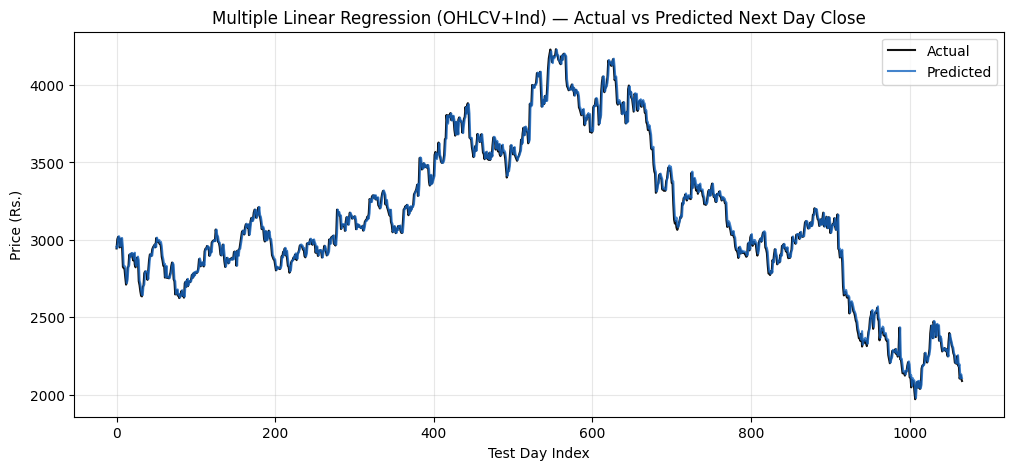

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(y_test.values, color='#111111', linewidth=1.5, label='Actual')
plt.plot(y_pred_B_2, color='#1565C0', linewidth=1.5, label='Predicted', alpha=0.8)
plt.xlabel('Test Day Index'); plt.ylabel('Price (Rs.)')
plt.title('Multiple Linear Regression (OHLCV+Ind) — Actual vs Predicted Next Day Close')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# ── Overfit / Underfitting Check — Multiple LR — OHLCV + Indicators (Set B) ─────────────────────────────
_y_tr_oc = model_B_2.predict(X_B_train_2)      # train predictions
_tr_m    = get_metrics(y_train, _y_tr_oc)
_te_m    = get_metrics(y_test,  y_pred_B_2)         # test predictions already computed

_r2_gap     = _tr_m['R2'] - _te_m['R2']
_mape_ratio = _te_m['MAPE'] / max(_tr_m['MAPE'], 1e-9)

if (_te_m['MAPE'] > 1.5 * _tr_m['MAPE']) or (_r2_gap > 0.05):
    _verdict = 'OVERFIT  ⚠️'
elif _tr_m['R2'] < 0.80:
    _verdict = 'UNDERFIT ⚠️'
else:
    _verdict = 'GOOD FIT ✅'

print("="*52)
print(f"  Overfit Check — Multiple LR — OHLCV + Indicators (Set B)")
print("="*52)
print(f"  Train MAPE : {_tr_m['MAPE']:.4f}%")
print(f"  Test  MAPE : {_te_m['MAPE']:.4f}%")
print(f"  MAPE Ratio : {_mape_ratio:.2f}x  (threshold: > 1.5x = OVERFIT)")
print(f"  Train R2   : {_tr_m['R2']:.6f}")
print(f"  Test  R2   : {_te_m['R2']:.6f}")
print(f"  R2 Gap     : {_r2_gap:.6f}  (threshold: > 0.05 = OVERFIT)")
print(f"  VERDICT    : {_verdict}")
print("="*52)

  Overfit Check — Multiple LR — OHLCV + Indicators (Set B)
  Train MAPE : 1.4280%
  Test  MAPE : 1.0235%
  MAPE Ratio : 0.72x  (threshold: > 1.5x = OVERFIT)
  Train R2   : 0.999485
  Test  R2   : 0.992408
  R2 Gap     : 0.007077  (threshold: > 0.05 = OVERFIT)
  VERDICT    : GOOD FIT ✅


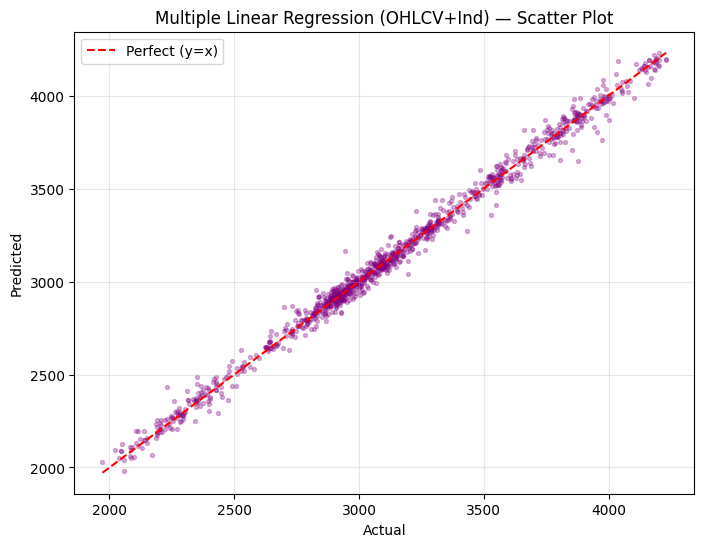

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test.values, y_pred_B_2, alpha=0.3, s=8, color='purple')
mn = min(y_test.min(), y_pred_B_2.min())
mx = max(y_test.max(), y_pred_B_2.max())
plt.plot([mn, mx], [mn, mx], 'r--', lw=1.5, label='Perfect (y=x)')
plt.xlabel('Actual'); plt.ylabel('Predicted')
plt.title('Multiple Linear Regression (OHLCV+Ind) — Scatter Plot')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

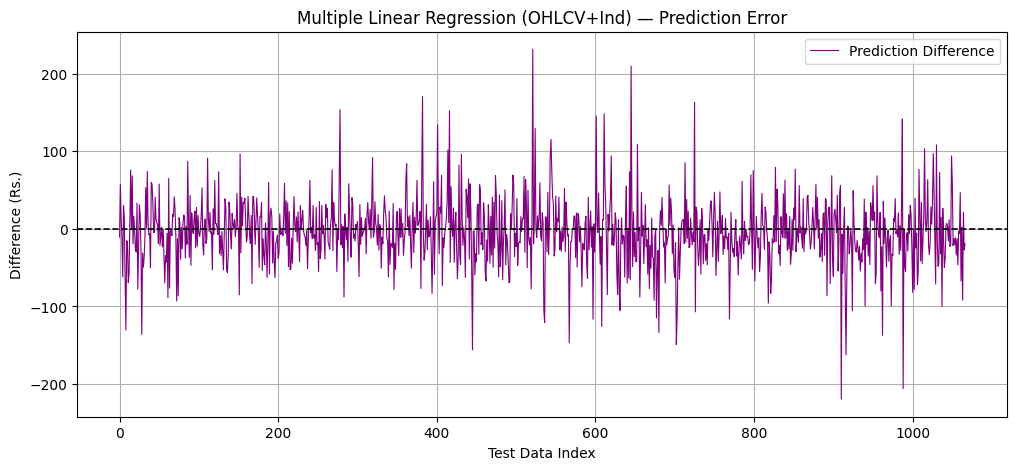

In [ ]:
residuals_B_2 = y_test.values - y_pred_B_2
plt.figure(figsize=(12, 5))
plt.plot(residuals_B_2, color='purple', linewidth=0.8, label='Prediction Difference')
plt.axhline(0, color='black', linestyle='--', linewidth=1.2)
plt.xlabel('Test Data Index'); plt.ylabel('Difference (Rs.)')
plt.title('Multiple Linear Regression (OHLCV+Ind) — Prediction Error')
plt.legend(); plt.grid(True)
plt.show()

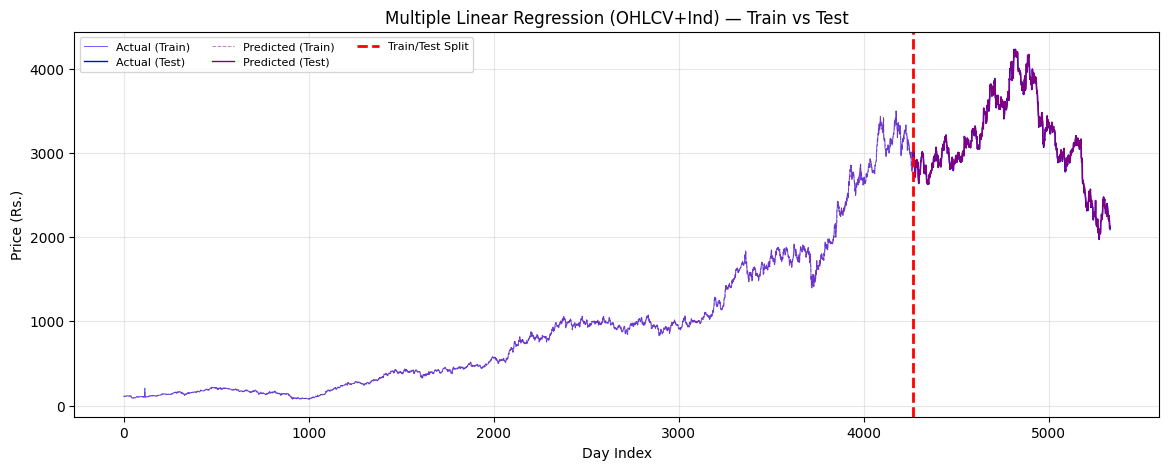

In [ ]:
y_train_pred_B_2 = model_B_2.predict(X_B_train_2)

plt.figure(figsize=(14, 5))
plt.plot(range(n_tr), y_train.values, color='blue', lw=0.7, alpha=0.6, label='Actual (Train)')
plt.plot(range(n_tr, n_tr+n_te), y_test.values, color='blue', lw=1.0, label='Actual (Test)')
plt.plot(range(n_tr), y_train_pred_B_2, color='purple', lw=0.7,
         alpha=0.5, linestyle='--', label='Predicted (Train)')
plt.plot(range(n_tr, n_tr+n_te), y_pred_B_2, color='purple', lw=1.0, label='Predicted (Test)')
plt.axvline(n_tr, color='red', lw=2, linestyle='--', label='Train/Test Split')
plt.title('Multiple Linear Regression (OHLCV+Ind) — Train vs Test')
plt.xlabel('Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(fontsize=8, ncol=3); plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
tr_metrics_B = get_metrics(y_train, y_train_pred_B_2)
te_metrics_B = metrics_B_2

print(f"==================================================")
print(f"  Overfit Check: Multiple Linear Regression — OHLCV + Indicators")
print(f"==================================================")
print(f"  Train MAPE : {tr_metrics_B['MAPE']:.4f}%")
print(f"  Test  MAPE : {te_metrics_B['MAPE']:.4f}%")
print(f"  Gap        : {te_metrics_B['MAPE'] - tr_metrics_B['MAPE']:+.4f}%")
print(f"  Train R2   : {tr_metrics_B['R2']:.6f}")
print(f"  Test  R2   : {te_metrics_B['R2']:.6f}")

if te_metrics_B['MAPE'] > 1.5 * tr_metrics_B['MAPE']:
    verdict_B = 'OVERFITTING'
elif tr_metrics_B['R2'] < 0.80 and te_metrics_B['R2'] < 0.80:
    verdict_B = 'UNDERFITTING'
else:
    verdict_B = 'GOOD FIT'
print(f"  Verdict    : {verdict_B}")

  Overfit Check: Multiple Linear Regression — OHLCV + Indicators
  Train MAPE : 1.4280%
  Test  MAPE : 1.0235%
  Gap        : -0.4044%
  Train R2   : 0.999485
  Test  R2   : 0.992408
  Verdict    : GOOD FIT


## Model 2C: Compare OHLCV vs OHLCV+Indicators — Multiple Linear Regression

In [ ]:
# ── Combined Predictions Table: Actual vs OHLCV (Set A) vs OHLCV+Indicators (Set B) ──
comparison_comb_2 = pd.DataFrame({
    'Date'                      : y_test.index,
    'Actual Next Day Close'     : y_test.values.round(2),
    'Pred (OHLCV Only)'         : y_pred_A_2.round(2),
    'Diff (OHLCV Only)'         : (y_test.values - y_pred_A_2).round(2),
    'Pred (OHLCV+Indicators)'   : y_pred_B_2.round(2),
    'Diff (OHLCV+Ind)'          : (y_test.values - y_pred_B_2).round(2),
})
print("Combined Predictions Comparison (Set A vs Set B) — Model 2 (Multiple Linear Regression):")
display(comparison_comb_2.head(10))

# ── Set B Full Feature Table: OHLCV + All 9 Technical Indicators (14 Features) ──
print("\nSet B Features (OHLCV + All Indicators) — Test Set First 10 Days:")
display(X_B_test.head(10).round(2))

# ── Side-by-Side Metric Comparison Table ──
comp_2 = pd.DataFrame({
    'Metric'          : ['MAE (Rs.)','RMSE (Rs.)','R2 Score','MAPE (%)','Dir. Acc (%)'],
    'OHLCV Only'      : [round(metrics_A_2[k],4) for k in ['MAE','RMSE','R2','MAPE','Dir_Acc']],
    'OHLCV+Indicators': [round(metrics_B_2[k],4) for k in ['MAE','RMSE','R2','MAPE','Dir_Acc']],
})
comp_2['Improvement'] = comp_2['OHLCV Only'] - comp_2['OHLCV+Indicators']
print("\nEvaluation Metrics Comparison: Multiple Linear Regression")
display(comp_2)


Combined Predictions Comparison (Set A vs Set B) — Model 2 (Multiple Linear Regression):


,Date,Actual Next Day Close,Pred (OHLCV Only),Diff (OHLCV Only),Pred (OHLCV+Indicators),Diff (OHLCV+Ind)
0,2022-05-31,2945.09,2953.61,-8.52,2955.73,-10.64
1,2022-06-01,3004.60,2945.77,58.83,2947.23,57.37
2,2022-06-02,3019.65,3005.07,14.58,3007.47,12.19
3,2022-06-03,3011.58,3021.86,-10.29,3023.93,-12.35
4,2022-06-06,2951.67,3011.46,-59.79,3013.98,-62.31
5,2022-06-07,2988.05,2954.41,33.65,2958.22,29.83
6,2022-06-08,3008.20,2987.37,20.83,2993.44,14.76
7,2022-06-09,2949.21,3007.45,-58.24,3012.71,-63.50
8,2022-06-10,2826.06,2951.00,-124.94,2956.58,-130.52
9,2022-06-13,2818.12,2826.96,-8.84,2833.40,-15.28



Set B Features (OHLCV + All Indicators) — Test Set First 10 Days:


,Open,High,Low,Close,Volume,MA_7,MA_30,EMA_12,EMA_26,MACD,RSI_14,Volatility,Daily_Return,Lag1_Close
Date,,,,,,,,,,,,,,
2022-05-31,2944.17,2969.84,2918.58,2953.12,4840965,2879.21,2996.18,2915.49,2971.56,-56.07,48.28,2.10,-0.32,2962.69
2022-06-01,2973.88,2973.88,2931.79,2945.09,1493835,2886.19,2993.44,2920.04,2969.59,-49.55,47.89,2.11,-0.27,2953.12
2022-06-02,2944.91,3012.50,2937.27,3004.60,2657939,2905.88,2990.23,2933.05,2972.19,-39.14,51.97,2.11,2.02,2945.09
2022-06-03,3036.55,3052.26,3011.80,3019.65,1913622,2940.05,2985.42,2946.37,2975.70,-29.33,55.61,1.38,0.50,3004.60
2022-06-06,3000.21,3030.93,2964.35,3011.58,1084210,2965.63,2980.81,2956.40,2978.36,-21.96,50.17,1.44,-0.27,3019.65
2022-06-07,2985.33,3000.96,2945.79,2951.67,2308256,2978.34,2976.08,2955.68,2976.38,-20.71,45.89,1.79,-1.99,3011.58
2022-06-08,2966.99,2996.66,2937.45,2988.05,2185707,2981.97,2972.62,2960.66,2977.25,-16.59,63.17,1.29,1.23,2951.67
2022-06-09,2971.24,3016.89,2943.24,3008.20,1279197,2989.83,2969.39,2967.97,2979.54,-11.57,62.70,1.28,0.67,2988.05
2022-06-10,2968.61,2978.27,2942.28,2949.21,1527582,2990.42,2963.53,2965.09,2977.29,-12.21,54.62,1.54,-1.96,3008.20



Evaluation Metrics Comparison: Multiple Linear Regression


,Metric,OHLCV Only,OHLCV+Indicators,Improvement
0,MAE (Rs.),31.1736,31.4171,-0.2435
1,RMSE (Rs.),43.4280,43.6813,-0.2533
2,R2 Score,0.9925,0.9924,0.0001
3,MAPE (%),1.0144,1.0235,-0.0091
4,Dir. Acc (%),50.1876,50.0938,0.0938


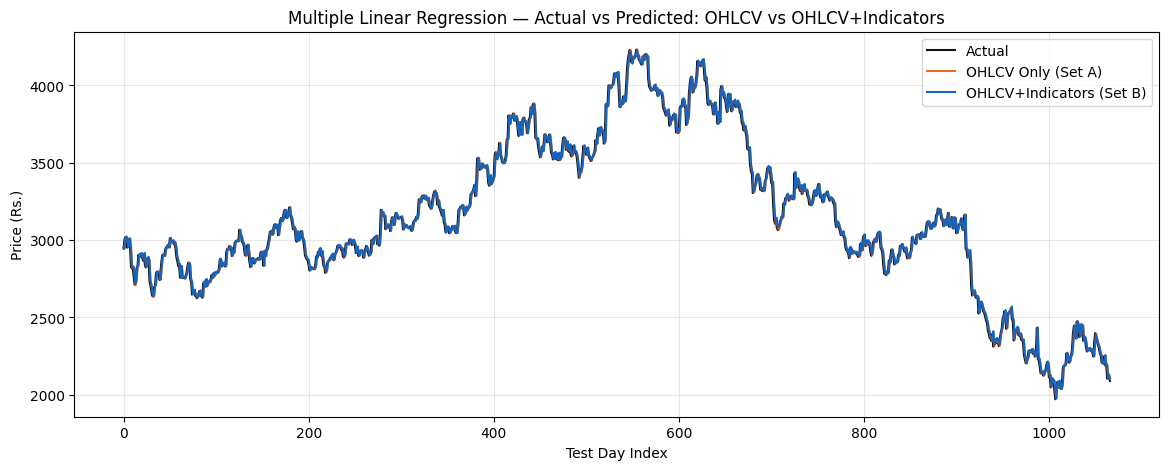

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(y_test.values,        color='#111111', lw=1.5, label='Actual')
plt.plot(y_pred_A_2, color='#E65100', lw=1.5, label='OHLCV Only (Set A)',       alpha=0.85)
plt.plot(y_pred_B_2, color='#1565C0', lw=1.5, label='OHLCV+Indicators (Set B)', )
plt.xlabel('Test Day Index'); plt.ylabel('Price (Rs.)')
plt.title('Multiple Linear Regression — Actual vs Predicted: OHLCV vs OHLCV+Indicators')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Store results for final comparison
all_results.append({
    'Model': 'Multiple Linear Regression', 'Set': 'OHLCV Only',
    'MAPE': metrics_A_2['MAPE'], 'R2': metrics_A_2['R2'],
    'MAE': metrics_A_2['MAE'],   'Dir_Acc': metrics_A_2['Dir_Acc'],
})
all_results.append({
    'Model': 'Multiple Linear Regression', 'Set': 'OHLCV+Indicators',
    'MAPE': metrics_B_2['MAPE'], 'R2': metrics_B_2['R2'],
    'MAE': metrics_B_2['MAE'],   'Dir_Acc': metrics_B_2['Dir_Acc'],
})
print(f"Multiple Linear Regression done! MAPE: A={metrics_A_2['MAPE']:.4f}%  B={metrics_B_2['MAPE']:.4f}%")

Multiple Linear Regression done! MAPE: A=1.0144%  B=1.0235%
